In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from pathlib import Path

In [ ]:
# Load the CSV file
file_path = 'data/gold_cad.csv'
data = pd.read_csv(file_path)

In [ ]:
# Convert the Date column to datetime
data['Date'] = pd.to_datetime(data['Date'])

In [ ]:
# Sort the data by date
data = data.sort_values('Date')

In [ ]:
data.head(15)

,Date,Close
0,2001-01-02,400.90
1,2001-01-03,401.68
2,2001-01-04,400.51
3,2001-01-05,401.92
4,2001-01-08,400.42
5,2001-01-09,399.73
6,2001-01-10,395.55
7,2001-01-11,394.50
8,2001-01-12,395.89
9,2001-01-16,396.72


In [ ]:
# Normalize the 'Close' values
scaler = MinMaxScaler(feature_range=(0, 1))
data['Close'] = scaler.fit_transform(data['Close'].values.reshape(-1, 1))

In [ ]:
# Create the classification labels: "up" if next day's price is higher
data['Target'] = (data['Close'].shift(-1) > data['Close']).astype(int)

In [ ]:
# Drop the last row
data = data[:-1]

In [ ]:
from sklearn.model_selection import train_test_split

# Prepare sequences of data
def create_sequences(data, sequence_length):
    X = []
    y = []
    for i in range(len(data) - sequence_length):
        X.append(data.iloc[i:i+sequence_length]['Close'].values)
        y.append(data.iloc[i + sequence_length]['Target'])
    return np.array(X), np.array(y)

In [ ]:
# Define sequence length
sequence_length = 10

In [ ]:
# Create sequences
X, y = create_sequences(data, sequence_length)

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN

# Build the RNN model
model = Sequential()
model.add(SimpleRNN(50, activation='relu', input_shape=(sequence_length, 1)))
model.add(Dense(1, activation='sigmoid'))  # For binary classification


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [23]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 50)                  │           2,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,955 (31.08 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,304 (20.72 KB)

In [ ]:
# Train the model
X_train_reshaped = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test_reshaped = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))
history = model.fit(X_train_reshaped, y_train, epochs=10000, batch_size=1000, validation_split=0.1)

Streaming output truncated to the last 5000 lines.
Epoch 7501/10000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6439 - loss: 0.6017 - val_accuracy: 0.5051 - val_loss: 0.7859
Epoch 7502/10000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6482 - loss: 0.5994 - val_accuracy: 0.4773 - val_loss: 0.8015
Epoch 7503/10000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6490 - loss: 0.5986 - val_accuracy: 0.4747 - val_loss: 0.7924
Epoch 7504/10000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6479 - loss: 0.6080 - val_accuracy: 0.4798 - val_loss: 0.7949
Epoch 7505/10000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6489 - loss: 0.6040 - val_accuracy: 0.4798 - val_loss: 0.7940
Epoch 7506/10000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6454 - loss: 0.6010 - val_accuracy: 0.4899 - val_loss: 0.7805
Epoch 7507/10000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6500 - loss: 0.6010 - val_accuracy: 0.4773 - val_loss: 0.8098
Epoch 7508/10000
4/4 ━━━━━━━━━━━

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt

# Predict the test set
y_pred = model.predict(X_test_reshaped)
y_pred_class = (y_pred > 0.5).astype(int)

31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step


In [24]:
from sklearn.metrics import accuracy_score

y_rnn_pred_binary = np.round(y_pred)

In [26]:
print("RNN LSTM Accuracy: %.2f" % (accuracy_score(y_test , y_rnn_pred_binary)))

RNN LSTM Accuracy: 0.50


In [27]:
#Confusion Matrix

#Importing the method from sklearn
from sklearn.metrics import confusion_matrix

In [29]:
#Confusion Matrix For RNN
tn_vader , fp_vader , fn_vader , tp_vader = confusion_matrix(y_test , y_rnn_pred_binary).ravel()



cm_vader_df = pd.DataFrame(
    {
        "Positive(1)":[f"TP={tp_vader}" , f"FP={fp_vader}"],
        "Negative(0)":[f"FN={fn_vader}" , f"TN={tn_vader}"],
    },
    index=["Positive(1)" , "Negative(0)"],
)
cm_vader_df.index.name = "Actual"
cm_vader_df.columns.name = "Predicted"
print("Confusion Matrix From VADER")
display(cm_vader_df)

Confusion Matrix From VADER


Predicted,Positive(1),Negative(0)
Actual,,
Positive(1),TP=314,FN=195
Negative(0),FP=299,TN=182


In [32]:
#Classification Report for the RNN LSTM Model
from sklearn.metrics import classification_report

print("Classification Report for the RNN LSTM Model")
print(classification_report(y_rnn_pred_binary , y_test))

Classification Report for the RNN LSTM Model
              precision    recall  f1-score   support

         0.0       0.38      0.48      0.42       377
         1.0       0.62      0.51      0.56       613

    accuracy                           0.50       990
   macro avg       0.50      0.50      0.49       990
weighted avg       0.53      0.50      0.51       990



In [33]:
from sklearn.metrics import roc_curve , auc

In [39]:
test_predictions_rnn = model.predict(X_test_reshaped , batch_size=1000)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 522ms/step


In [41]:
#Data For ROC Curve - RNN LSTM Model
fpr_test_rnn , tpr_test_rnn , thresholds_test_rnn = roc_curve(y_test , test_predictions_rnn)

In [42]:
#AUC For RNN LSTM Model
auc_test_rnn = auc(fpr_test_rnn , tpr_test_rnn)
auc_test_rnn = round(auc_test_rnn , 4)

In [43]:
#Data frame For Plot
roc_df_test_rnn = pd.DataFrame({"FPR Test":fpr_test_rnn , "TPR Test":tpr_test_rnn})

Exception ignored in: <function _xla_gc_callback at 0x7be4bc0ad090>
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/jax/_src/lib/__init__.py", line 98, in _xla_gc_callback
    def _xla_gc_callback(*args):
KeyboardInterrupt: 


<Axes: title={'center': 'Test ROC Curve for the RNN LSTM Model (AUC =0.4917)'}, xlabel='FPR Test'>

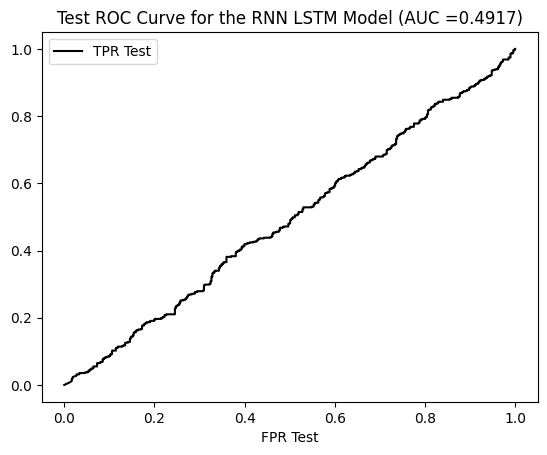

In [ ]:
#Plot
roc_df_test_rnn.plot(x="FPR Test" ,
                     y="TPR Test",
                     color ="black",
                     style='-',
                     xlim=([-0.05,1.05]),
                     title =f"Test ROC Curve for the RNN LSTM Model (AUC ={auc_test_rnn})"
)
#

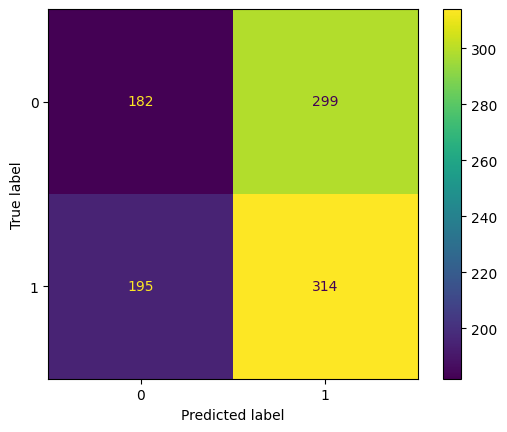

In [19]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_class)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [20]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

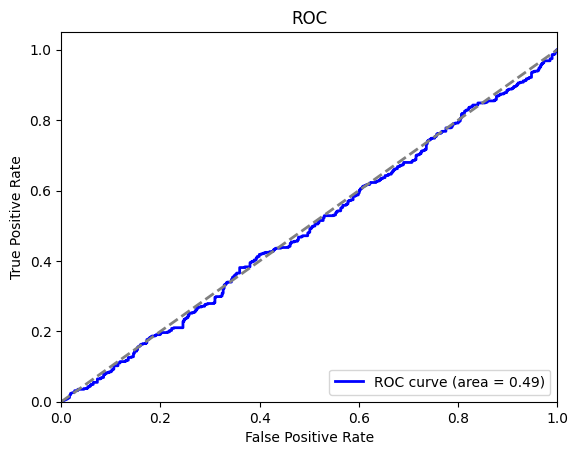

In [22]:
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC')
plt.legend(loc='lower right')
plt.show()